# **Laboratorio 10 · Explicabilidad**

En este notebook aplicamos Integrated Gradients (IG) sobre el modelo final del proyecto, el LSTM de 28 días con 9 cuantiles (iteración 5), sin volver a entrenarlo. Todas las explicaciones se calculan sobre la mediana de la predicción del día siguiente, con una línea base de semana "plana" y una semilla fija, de tal forma que las figuras y tablas del informe se puedan regenerar corriendo el notebook de principio a fin.

## **0. Modelo y datos de prueba**

Primero cargamos los pesos de la mejor época de la iteración 5 y armamos las ventanas de prueba de The Bread Basket igual que en el notebook 07 (`first_offset=28`). Luego comprobamos que el modelo reproduce el WAPE reportado en el proyecto final, para asegurar que estamos explicando exactamente el mismo modelo.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "explainableAi" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.models import LSTMForecaster
from src.training import DEVICE, predict
from src.windows import Windows, make_windows

SEED = 123
QUANTILES = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]
MODELS, RESULTS = ROOT / "models", ROOT / "results"

# Misma configuración que ganó la búsqueda del notebook 06 (2 capas de 32 neuronas).
search = pd.read_csv(RESULTS / "02_busqueda_lstm.csv").sort_values("WAPE val")
config = dict(hidden=int(search.iloc[0]["neuronas"]), layers=int(search.iloc[0]["capas"]))
model = LSTMForecaster(4, 3, quantiles=len(QUANTILES), **config)
model.load_state_dict(torch.load(MODELS / "05_lstm_cuantiles.pt", map_location=DEVICE))
model.to(DEVICE).eval()
print(f"Modelo cargado en {DEVICE} | parámetros: {sum(p.numel() for p in model.parameters()):,}")

Modelo cargado en mps | parámetros: 20,863


In [2]:
df = pd.read_parquet(ROOT / "data" / "processed" / "unified.parquet")
test = make_windows(df, 28, ["test"], first_offset=28)
keep = (test.meta["dataset"] == "bread_basket").to_numpy()
bb = Windows(past=test.past[keep], future=test.future[keep], target=test.target[keep],
             mask=test.mask[keep], scale=test.scale[keep], meta=test.meta[keep].reset_index(drop=True))

# Predicción en unidades: (ventanas, 7 días, 9 cuantiles) por la escala de cada ventana.
ladder = predict(model, bb) * bb.scale[:, None, None]
median = ladder[..., 0]
actual = bb.target * bb.scale[:, None]
open_days = bb.mask == 1
wape = np.abs(median - actual)[open_days].sum() / actual[open_days].sum()
reported = pd.read_csv(RESULTS / "07_prueba_bread_basket.csv", index_col=0).loc["LSTM cuantiles (iteración 5)", "WAPE"]

print(f"Ventanas de prueba: {len(bb):,} | productos: {bb.meta['product_id'].nunique()} | "
      f"días predichos: {bb.meta['first_date'].min().date()} a {bb.meta['first_date'].max().date()}")
print(f"WAPE de la mediana: {wape:.4f} | reportado en el notebook 07: {reported:.4f}")
assert abs(wape - reported) < 1e-4, "El modelo no reproduce el resultado del proyecto final"

Ventanas de prueba: 2,464 | productos: 20 | días predichos: 2016-11-27 a 2017-04-03
WAPE de la mediana: 0.4133 | reportado en el notebook 07: 0.4133


## **1. Línea base e Integrated Gradients**

La línea base es una semana "plana": cada día abierto de la ventana tiene la venta promedio de esos mismos días abiertos, los días cerrados quedan en 0 y el calendario (días abiertos y feriados) es el mismo de la ventana real. Así, IG mide cuánto aporta cada día frente a una semana sin altibajos con el mismo nivel de ventas, y como el calendario es igual en ambas, sus variables no reciben aporte.

IG se calcula sobre una sola salida del modelo, la mediana (cuantil 0.50) del día siguiente, con 50 pasos en el camino entre la línea base y la ventana real. Las variables de cada día de entrada son, en este orden, la venta normalizada, si el local abrió, si fue feriado y si hay un feriado en los próximos 2 días.

In [3]:
from captum.attr import IntegratedGradients

N_STEPS = 50
FEATURES = ["venta", "abierto", "feriado", "feriado próximo"]


def flat_baseline(past):
    """Semana plana: la venta promedio de los días abiertos en cada día abierto, 0 en los cerrados y el mismo calendario."""
    base = past.copy()
    is_open = past[:, :, 1] == 1
    mean_open = (past[:, :, 0] * is_open).sum(axis=1) / np.maximum(is_open.sum(axis=1), 1)
    base[:, :, 0] = np.where(is_open, mean_open[:, None], 0.0)
    return base


def next_day_median(past, future):
    """La salida que se explica: la mediana (cuantil 0.50) del día siguiente, en escala normalizada."""
    return model(past, future)[:, 0, 0]


ig = IntegratedGradients(next_day_median)


def explain(windows, batch=256):
    """Aportes de IG (ventanas, 28 días, 4 variables) y su diferencia con la completitud, en escala normalizada."""
    attributions, deltas = [], []
    for i in range(0, len(windows.past), batch):
        past = torch.from_numpy(windows.past[i:i + batch]).to(DEVICE)
        future = torch.from_numpy(windows.future[i:i + batch]).to(DEVICE)
        base = torch.from_numpy(flat_baseline(windows.past[i:i + batch])).to(DEVICE)
        attr, delta = ig.attribute(past, baselines=base, additional_forward_args=(future,),
                                   n_steps=N_STEPS, return_convergence_delta=True)
        attributions.append(attr.detach().cpu().numpy())
        deltas.append(delta.detach().cpu().numpy())
    return np.concatenate(attributions), np.concatenate(deltas)

Para comprobar que la línea base y la completitud funcionan, la probamos con el pan del sábado 18 de febrero de 2017, el mismo ejemplo del informe del proyecto final.

In [4]:
dates = pd.to_datetime(bb.meta["first_date"])
example = int(np.flatnonzero((bb.meta["product_id"] == "bread_basket_bread").to_numpy() & (dates == "2017-02-18").to_numpy())[0])
one = Windows(past=bb.past[[example]], future=bb.future[[example]], target=bb.target[[example]],
              mask=bb.mask[[example]], scale=bb.scale[[example]], meta=bb.meta.iloc[[example]])
attr, delta = explain(one)
base = flat_baseline(one.past)
scale = one.scale[0]

with torch.no_grad():
    pred_real = next_day_median(torch.from_numpy(one.past).to(DEVICE), torch.from_numpy(one.future).to(DEVICE)).item()
    pred_base = next_day_median(torch.from_numpy(base).to(DEVICE), torch.from_numpy(one.future).to(DEVICE)).item()

print("Mismo calendario que la ventana real:", np.array_equal(base[0, :, 1:], one.past[0, :, 1:]))
print(f"Venta promedio de los días abiertos: real {one.past[0, :, 0][one.past[0, :, 1] == 1].mean() * scale:.2f} | línea base {base[0, :, 0][base[0, :, 1] == 1].mean() * scale:.2f} unidades")
print(f"Predicción real: {pred_real * scale:.2f} | con la línea base: {pred_base * scale:.2f} | venta real: {one.target[0, 0] * scale:.0f} unidades")
print(f"Suma de los aportes: {attr.sum() * scale:.3f} | diferencia de las predicciones: {(pred_real - pred_base) * scale:.3f} unidades")
print(f"Aporte del calendario (debe ser 0): {np.abs(attr[0, :, 1:]).sum():.2e} | delta de completitud: {abs(delta[0]) * scale:.2e} unidades")

Mismo calendario que la ventana real: True
Venta promedio de los días abiertos: real 21.86 | línea base 21.86 unidades
Predicción real: 34.37 | con la línea base: 22.16 | venta real: 42 unidades
Suma de los aportes: 12.231 | diferencia de las predicciones: 12.204 unidades
Aporte del calendario (debe ser 0): 0.00e+00 | delta de completitud: 2.66e-02 unidades


## **2. Selección de las 5 instancias**

Cada instancia es una ventana de prueba de The Bread Basket cuyo día siguiente el local abrió, y se elige con una regla fija para no escoger a mano los casos que más convienen:

1. **Acierto con alta confianza:** entre el 10 % de ventanas con la escalera de cuantiles más angosta respecto a su mediana (el modelo "seguro"), la de menor error.
2. **Error:** la de mayor error respecto al nivel de ventas de su ventana (la escala), para que no ganen siempre los productos que venden 0 o 1 unidades.
3. **Cercano al umbral:** la mediana cuya parte decimal está más cerca de .5, donde un cambio mínimo cambia el entero al redondear.
4. **Subgrupo de interés:** al azar, con la semilla fija, entre los productos que venden menos de 2 unidades al día en promedio.
5. **Semana atípica:** el pan del sábado 7 de enero de 2017, cuya ventana incluye Navidad y Año Nuevo con días cerrados.

In [5]:
pred1, act1 = median[:, 0], actual[:, 0]
low, high = ladder[:, 0, 0], ladder[:, 0, -1]
opened = bb.mask[:, 0] == 1
error = np.abs(pred1 - act1)
names = bb.meta["product_id"].str.replace("bread_basket_", "")
rng = np.random.default_rng(SEED)

chosen = {}
width = (high - low) / np.maximum(low, 1)
narrow = opened & (width <= np.quantile(width[opened], 0.10))
chosen["Acierto con alta confianza"] = int(np.flatnonzero(narrow)[np.argmin(error[narrow])])

relative = np.where(opened, error / bb.scale, -1)
chosen["Error"] = int(np.argmax(relative))

threshold = np.where(opened, np.abs(pred1 % 1 - 0.5), np.inf)
chosen["Cercano al umbral"] = int(np.argmin(threshold))

daily = (actual * bb.mask).sum(axis=1) / np.maximum(bb.mask.sum(axis=1), 1)
small = names.groupby(names).transform(lambda s: daily[s.index].mean()).to_numpy() < 2
candidates = np.flatnonzero(opened & small & ~np.isin(np.arange(len(bb)), list(chosen.values())))
chosen["Subgrupo: producto que vende poco"] = int(rng.choice(candidates))

chosen["Semana atípica"] = int(np.flatnonzero((names == "bread").to_numpy() & (dates == "2017-01-07").to_numpy())[0])
assert len(set(chosen.values())) == 5, "Las instancias deben ser distintas"

instances = pd.DataFrame({
    "caso": list(chosen),
    "producto": names.iloc[list(chosen.values())].to_numpy(),
    "fecha": dates.iloc[list(chosen.values())].dt.strftime("%a %d %b %Y").to_numpy(),
    "mediana": pred1[list(chosen.values())].round(2),
    "cuantil 0.90": high[list(chosen.values())].round(2),
    "venta real": act1[list(chosen.values())].round(0),
    "error": error[list(chosen.values())].round(2),
})
instances

,caso,producto,fecha,mediana,cuantil 0.90,venta real,error
0,Acierto con alta confianza,cake,Sun 15 Jan 2017,6.020000,8.20,6.0,0.020000
1,Error,scone,Sat 04 Mar 2017,2.560000,6.19,22.0,19.440001
2,Cercano al umbral,soup,Mon 23 Jan 2017,0.500000,2.05,5.0,4.500000
3,Subgrupo: producto que vende poco,alfajores,Tue 13 Dec 2016,1.600000,5.27,3.0,1.400000
4,Semana atípica,bread,Sat 07 Jan 2017,19.709999,26.18,36.0,16.290001


## **3. Explicaciones locales**

Calculamos IG para las 5 instancias y graficamos, para cada una, la venta de cada día de la ventana (línea) y su aporte a la predicción en unidades (barras): azul si empujó la predicción hacia arriba frente a la semana plana, y rojo si la empujó hacia abajo. Las líneas punteadas marcan los días de la ventana que caen en el mismo día de la semana que el día predicho, y los puntos rojos los días en que el local cerró. Como el calendario no recibe aporte con esta línea base, solo se grafica el aporte de la venta.

In [6]:
import matplotlib.pyplot as plt

FIGURES = Path.cwd() / "figuras"
FIGURES.mkdir(exist_ok=True)
WEEKDAYS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
MONTHS = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
          "septiembre", "octubre", "noviembre", "diciembre"]


def spanish_date(day):
    return f"{WEEKDAYS[day.dayofweek]} {day.day} de {MONTHS[day.month - 1]} de {day.year}"


idx = list(chosen.values())
local = Windows(past=bb.past[idx], future=bb.future[idx], target=bb.target[idx],
                mask=bb.mask[idx], scale=bb.scale[idx], meta=bb.meta.iloc[idx].reset_index(drop=True))
local_attr, local_delta = explain(local)
sales_attr = local_attr[:, :, 0] * local.scale[:, None]   # aporte de la venta de cada día, en unidades

with torch.no_grad():
    base_pred = next_day_median(torch.from_numpy(flat_baseline(local.past)).to(DEVICE),
                                torch.from_numpy(local.future).to(DEVICE)).cpu().numpy() * local.scale

summary = instances.assign(
    **{"predicción con línea base": base_pred.round(2),
       "suma de aportes": sales_attr.sum(axis=1).round(2),
       "delta de completitud": (np.abs(local_delta) * local.scale).round(3)})
summary[["caso", "producto", "mediana", "predicción con línea base", "suma de aportes", "delta de completitud"]]

,caso,producto,mediana,predicción con línea base,suma de aportes,delta de completitud
0,Acierto con alta confianza,cake,6.020000,6.53,-0.51,0.000
1,Error,scone,2.560000,2.97,-0.42,0.007
2,Cercano al umbral,soup,0.500000,0.70,-0.19,0.000
3,Subgrupo: producto que vende poco,alfajores,1.600000,3.04,-1.45,0.011
4,Semana atípica,bread,19.709999,18.76,0.93,0.023


/var/folders/rb/f0_7lb1n5xj5bnjy4wqq36b80000gn/T/ipykernel_51542/1891007481.py:17: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  for day in days[days.dayofweek == target_day.dayofweek]:
/var/folders/rb/f0_7lb1n5xj5bnjy4wqq36b80000gn/T/ipykernel_51542/1891007481.py:17: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  for day in days[days.dayofweek == target_day.dayofweek]:
/var/folders/rb/f0_7lb1n5xj5bnjy4wqq36b80000gn/T/ipykernel_51542/184682392.py:11: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  return f"{WEEKDAYS[day.dayofweek]} {day.day} de {MONTHS[day.month - 1]} de {day.year}"
/var/folders/rb/f0_7lb1n5xj5bnjy4wqq36b80000gn/T/ipykernel_51542/1891007481.py:17: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in

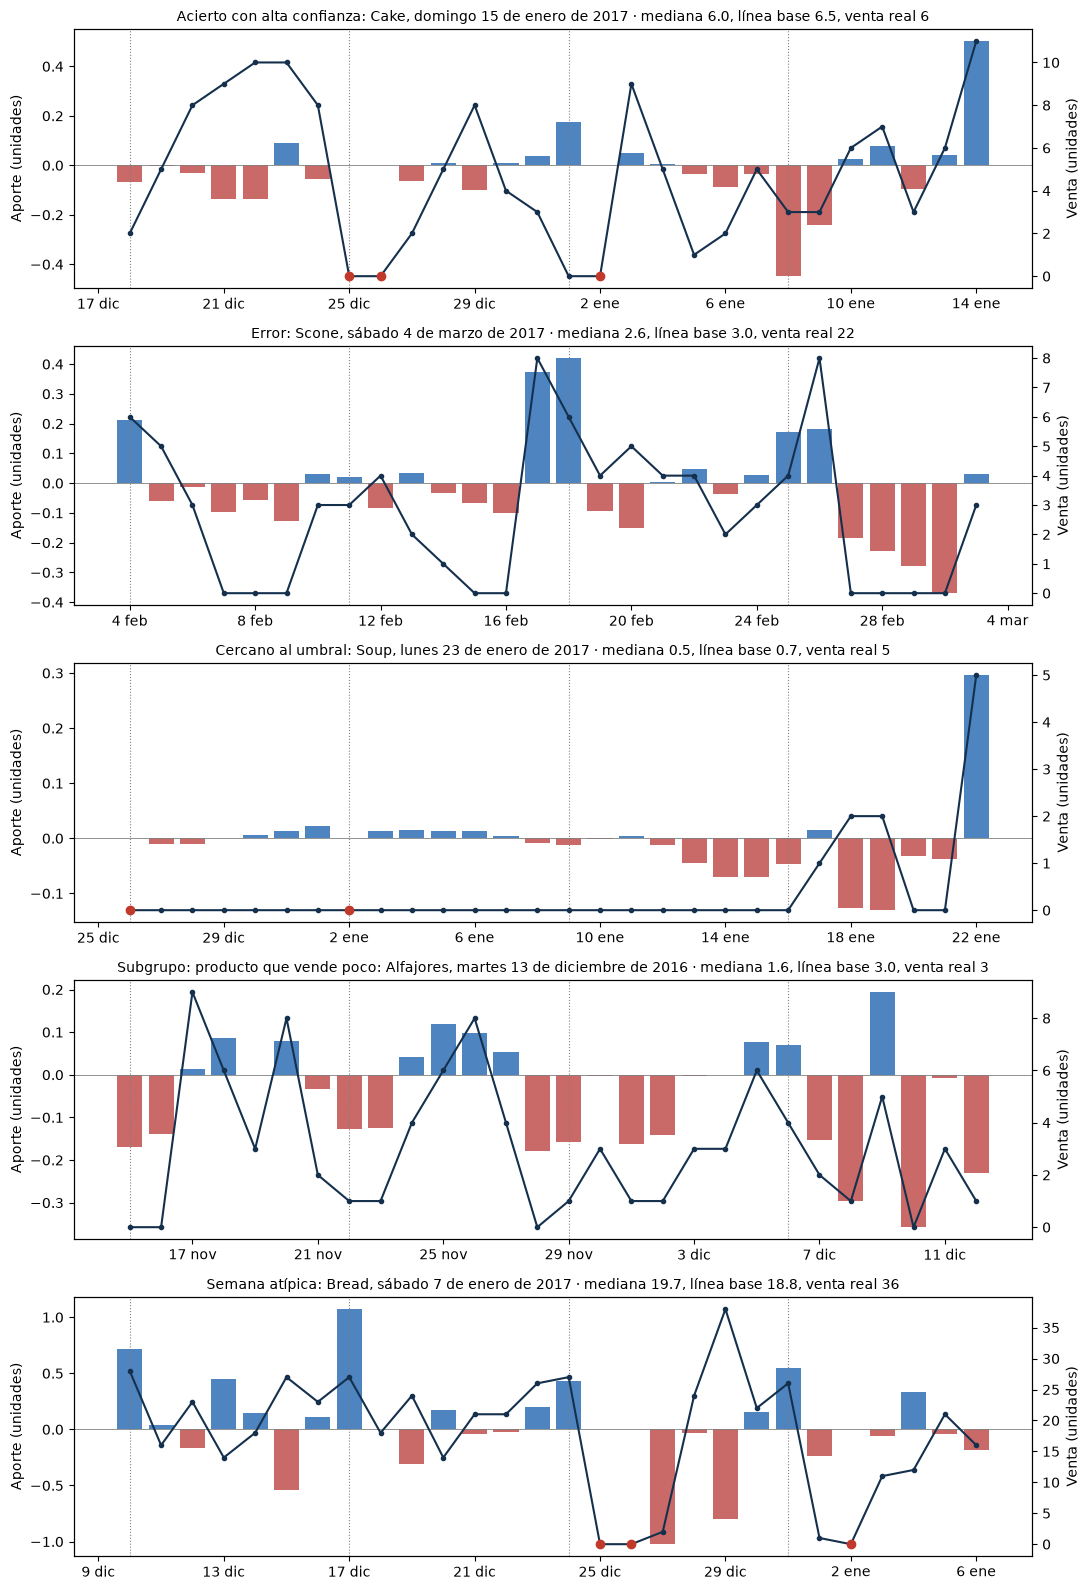

In [7]:
import matplotlib.dates as mdates

SHORT = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
short_date = plt.FuncFormatter(lambda x, _: f"{mdates.num2date(x).day} {SHORT[mdates.num2date(x).month - 1]}")

fig, axes = plt.subplots(len(idx), 1, figsize=(11, 3.2 * len(idx)))
for k, (ax, case) in enumerate(zip(axes, chosen)):
    target_day = dates.iloc[idx[k]]
    days = pd.date_range(end=target_day - pd.Timedelta(days=1), periods=28)
    sales = local.past[k, :, 0] * local.scale[k]
    closed = local.past[k, :, 1] == 0
    ax.bar(days, sales_attr[k], color=["#2f6fb5" if v >= 0 else "#c0504d" for v in sales_attr[k]], alpha=0.85)
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set_ylabel("Aporte (unidades)")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
    ax.xaxis.set_major_formatter(short_date)
    for day in days[days.dayofweek == target_day.dayofweek]:
        ax.axvline(day, color="gray", linestyle=":", linewidth=0.8)
    twin = ax.twinx()
    twin.plot(days, sales, color="#14304d", marker="o", markersize=3)
    twin.scatter(days[closed], sales[closed], color="#c0392b", zorder=3)
    twin.set_ylabel("Venta (unidades)")
    name = names.iloc[idx[k]].replace("_", " ").capitalize()
    ax.set_title(f"{case}: {name}, {spanish_date(target_day)} · mediana {median[idx[k], 0]:.1f}, "
                 f"línea base {base_pred[k]:.1f}, venta real {actual[idx[k], 0]:.0f}", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / "explicaciones_locales.png", dpi=200, facecolor="white")
plt.show()

## **4. Explicación global**

Para la visión agregada calculamos IG, con la misma línea base, sobre todas las ventanas de prueba de The Bread Basket cuyo día siguiente el local abrió. Los aportes se dejan en la escala normalizada, es decir, divididos entre la escala de cada ventana, para que un producto que vende 30 unidades al día no pese más que uno que vende 3. Luego se promedian por días hacia atrás de dos formas: en valor absoluto, que mide cuánto pesa cada día sin importar la dirección, y con su signo, que indica si en promedio empuja la predicción hacia arriba o hacia abajo. También medimos el tiempo de cálculo, para la discusión sobre su costo.

In [8]:
import time

open_idx = np.flatnonzero(opened)
sample = Windows(past=bb.past[open_idx], future=bb.future[open_idx], target=bb.target[open_idx],
                 mask=bb.mask[open_idx], scale=bb.scale[open_idx], meta=bb.meta.iloc[open_idx].reset_index(drop=True))

start = time.perf_counter()
global_attr, global_delta = explain(sample)
seconds = time.perf_counter() - start

days_back = np.arange(28, 0, -1)   # la posición 0 de la ventana es el día más lejano (hace 28 días)
sales_global = global_attr[:, :, 0]
by_day = pd.DataFrame({
    "valor absoluto": np.abs(sales_global).mean(axis=0),
    "con signo": sales_global.mean(axis=0),
}, index=pd.Index(days_back, name="días hacia atrás")).sort_index()

print(f"Ventanas explicadas: {len(sample):,} | tiempo: {seconds:.1f} s ({seconds / len(sample) * 1000:.2f} ms por predicción en {DEVICE})")
print(f"Delta de completitud (escala normalizada): mediana {np.median(np.abs(global_delta)):.4f} | máximo {np.abs(global_delta).max():.4f}")
by_day.round(4).head(8)

Ventanas explicadas: 2,408 | tiempo: 2.1 s (0.86 ms por predicción en mps)
Delta de completitud (escala normalizada): mediana 0.0013 | máximo 0.0492


,valor absoluto,con signo
días hacia atrás,,
1,0.0375,-0.0013
2,0.0327,-0.0060
3,0.0259,-0.0066
4,0.0290,-0.0059
5,0.0305,-0.0081
6,0.0331,-0.0077
7,0.0537,0.0134
8,0.0296,-0.0041


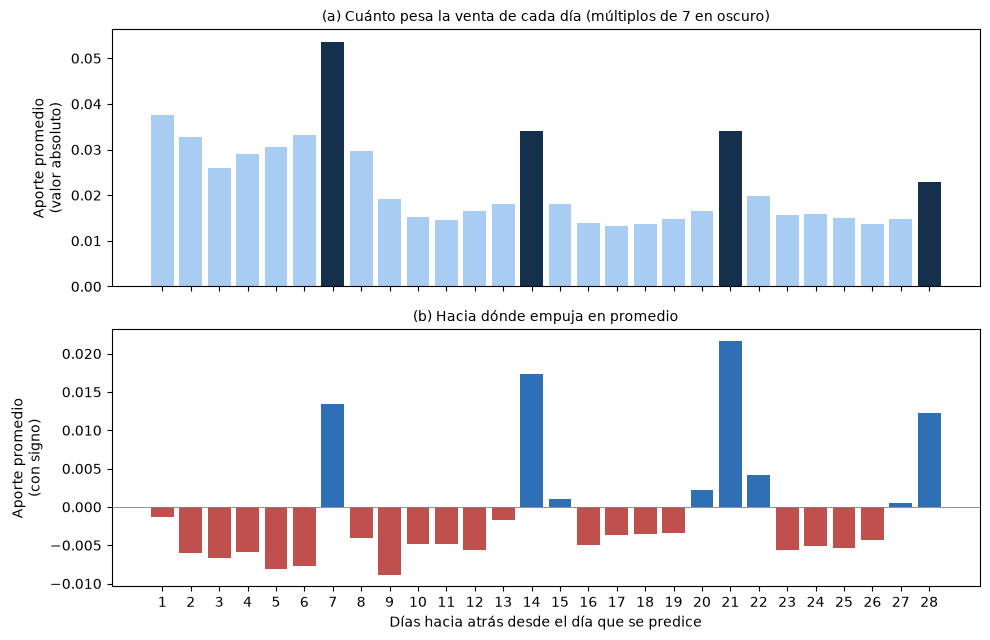

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
colors = ["#14304d" if d % 7 == 0 else "#a9ccf2" for d in by_day.index]
ax1.bar(by_day.index, by_day["valor absoluto"], color=colors)
ax1.set_ylabel("Aporte promedio\n(valor absoluto)")
ax1.set_title("(a) Cuánto pesa la venta de cada día (múltiplos de 7 en oscuro)", fontsize=10)
ax2.bar(by_day.index, by_day["con signo"], color=["#2f6fb5" if v >= 0 else "#c0504d" for v in by_day["con signo"]])
ax2.axhline(0, color="gray", linewidth=0.6)
ax2.set_ylabel("Aporte promedio\n(con signo)")
ax2.set_title("(b) Hacia dónde empuja en promedio", fontsize=10)
ax2.set_xticks(range(1, 29))
ax2.set_xlabel("Días hacia atrás desde el día que se predice")
fig.tight_layout()
fig.savefig(FIGURES / "explicacion_global.png", dpi=200, facecolor="white")
plt.show()